### Laboratorium 4, cześć 2: Transformacja Hougha

#### _Fabuła_
_Budujemy aplikację do szkolenia snookerzystów. Jej celem będzie, między innymi, analiza pozycji i sugerowanie zagrań. Naturalnie, podstawą działania aplikacji musi być funkcjonalność detekcji bil i określenia ich pozycji w układzie współrzędnych stołu. W dalszych etapach określane będą geometryczne relacje między bilami i łuzami - ich implementacją zajmie się jednak inny zespół._

#### Zadanie
Twoim celem będzie wykonanie detekcji **bil** oraz **band** za pomocą transformacji Hougha.
Przygotujesz potok przetwarzania przyjmujący obraz kolorowy w przestrzeni BGR/RGB a zwracający dwie kolekcje: jedną reprezentującą okręgi (bile), drugą - linie/odcinki (bandy) lub punkty (narożniki stołu).
Format tych kolekcji jest dowolny, szczegóły implementacji potoku podobnie.
W ogólności, potok powinien składać się z:
* etapu przetwarzania wstępnego - skorzystaj ze swojego ulubionego detektora krawędzi,
* wykonania transformacji Hougha dla linii ([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) do wykrycia band,
* wykonania transformacji Hougha dla okręgów ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) do wykrycia bil,
* przetwarzania końcowego wyników transformacji (np. usunięcie nadmiarowych/fałszywych detekcji).

Zaimplementuj również funkcję prezentującą wyniki w formie wizualnej, tj. rysującej wykryte obiekty na kopii obrazu wejściowego.

Dane są cztery obrazy.
Staraj się prowadzić eksperymenty na jednym czy dwóch, a następnie zaprezentować wyniki na pozostałych.

#### Oczekiwane rezultaty
1. Zacznij od znalezienia odpowiednich parametrów detektora krawędzi - jeśli na tym etapie wyniki będą słabe, to dalej będzie tylko gorzej (_garbage-in, garbage-out_). Nie skupiaj się na badaniu ich wpływu na wyniki końcowe, a jedynie przedstaw efekt przetwarzania wstępnego, tj. jak wygląda obraz, na którym wykonywana będzie TH. Ta część zadania będzie oceniana binarnie: dobrze/źle.
2. Kalibracja parametrów transformacji Hougha: zadanie **NIE** polega na zrobieniu grid searchu po parametrach TH (wykonanie go nie jest _zabronione_, po prostu nie umieszczaj go w notatniku). Interesujące jest jedynie zrozumienie działania poszczególnych parametrów i ich wpływu na wyniki - pozostaw w notatniku jedynie kilka przykładowych wyników, takich które ilustrują dokonane przez Ciebie wybory parametrów (_ustawiam parametr $x$ na wartość $x_0$, bo przy wartości $x_1$ działo się tak a tak_).
3. Demonstracja wyników na pozostałych obrazach: przedstaw obraz wejściowy, wykryte krawędzie, wykryte obiekty. Efektem powinny być 4 (lub 6) linii reprezentujących bandy, oraz zbiór okręgów odpowiadających bilom (w idealnym przypadku 1:1, ale nie musisz poświęcać długich godzin na wyeliminowaniu _wszystkich_ błędów, ważniejsze jest by umieć wyjaśnić, skąd się wzięły).


#### Literatura
1. Dokumentacja funkcji([`cv2.HoughLines`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga0b7ee275f89bb1a799ab70a42131f39d)) i ([`cv2.HoughCircles`](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga47849c3be0d0406ad3ca45db65a25d2d)) - działanie parametrów jest bardzo dobrze opisane.
2. Jeśli chcesz poznać TH "od środka" - [tutaj](https://medium.com/@alb.formaggio/implementing-the-hough-transform-from-scratch-09a56ba7316b) ktoś zaimplementował ją od zera. Czytając, uważaj tylko, by nie powtórzyć po Alberto jego błędu (krawędzie!)
3. Źródło danych do zadania: kompilacja [TOP 40 SHOTS of 2025 British Open](https://www.youtube.com/watch?v=5oZ3fIF9qog) autorstwa GTKomissaRa.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

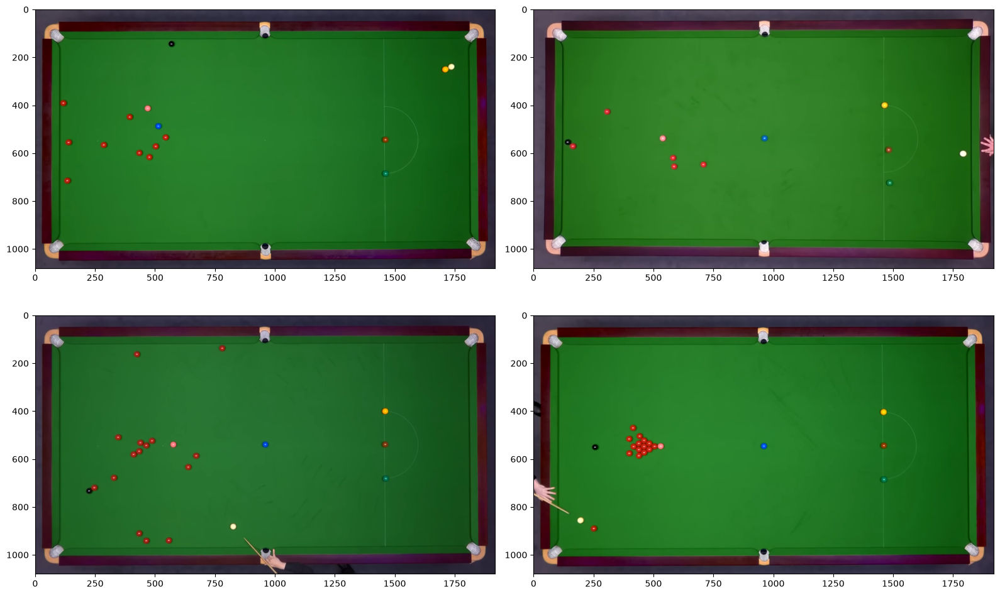

In [2]:
# zbiór danych
mcgill = cv2.imread('Lab4_dane/mcgill.png')
trump = cv2.imread('Lab4_dane/trump.png')
zhao = cv2.imread('Lab4_dane/zhao.png')
mcgill2 = cv2.imread('Lab4_dane/mcgill2.png')
assert all(x is not None for x in (mcgill, trump, zhao, mcgill2)), 'Nie wczytano obrazów - sprawdź ścieżkę'
# tu wyświetlone są wszystkie naraz w pomniejszeniu
# w eksperymentach staraj się wyświetlać je w dużym rozmiarze (albo używaj RoI)
_, axes = plt.subplots(2, 2, figsize=(16,10))
axes.ravel()[0].imshow(mcgill[..., ::-1])
axes.ravel()[1].imshow(trump[..., ::-1])
axes.ravel()[2].imshow(zhao[..., ::-1])
axes.ravel()[3].imshow(mcgill2[..., ::-1])
plt.tight_layout()

In [3]:
# funkcje pomocnicze do wyświetlania
def show(img, title=None, figsize=(16, 9), ax=None):
    """Wyświetla obraz BGR (3 kanały) lub jednokanałowy."""
    if ax is None:
        _, ax = plt.subplots(figsize=figsize)
    if img.ndim == 3:
        ax.imshow(img[..., ::-1])
    else:
        ax.imshow(img, cmap='gray')
    ax.set_title(title); ax.axis('off')
    return ax

def show_grid(imgs, titles, ncols=2, figsize=(18, 10)):
    nrows = int(np.ceil(len(imgs) / ncols))
    _, axes = plt.subplots(nrows, ncols, figsize=figsize)
    for ax in np.ravel(axes):
        ax.axis('off')
    for ax, img, t in zip(np.ravel(axes), imgs, titles):
        show(img, t, ax=ax)
    plt.tight_layout()

# RoI używane do podglądu z bliska (wiersze, kolumny)
ROI_PACK = (slice(420, 620), slice(330, 580))    # trójkąt czerwonych w mcgill2
ROI_CORNER = (slice(0, 300), slice(0, 420))      # lewy górny róg stołu

Eksperymenty prowadzę na obrazach **`mcgill`** i **`mcgill2`** (ten drugi zawiera ciasno ułożony trójkąt czerwonych bil - najtrudniejszy przypadek dla detekcji okręgów).
Obrazy **`trump`** i **`zhao`** służą wyłącznie do demonstracji końcowej.

## 1. Przetwarzanie wstępne

Potok przetwarzania wstępnego:
1. kanał **L\*** z przestrzeni Lab (jasność percepcyjna),
2. rozmycie Gaussa 5×5 - usuwa szum kompresji i fakturę sukna,
3. detektor Canny'ego z progami 30 / 60.

Dlaczego L\* zamiast zwykłej skali szarości: czerwone bile na zielonym suknie mają w skali szarości prawie tę samą jasność co tło, więc ich krawędzie wychodziły niepełne (pojedyncze łuki od strony cienia).
L\* jest nieliniowe i „rozciąga” ciemne tony, dzięki czemu ciemne obrzeże bili daje wyraźnie silniejszy gradient (ok. 1,5× na brzegu czerwonej bili).
Zachowuje też ciemne szczeliny między stykającymi się bilami w trójkącie - tego nie dawał np. obraz „odległości od koloru sukna”, w którym cały trójkąt zlewał się w jedną plamę.

Progi Canny'ego są niskie, bo kontrast bila/sukno jest mały. Te same wartości trafiają później do `HoughCircles` (`param1` = górny próg Canny'ego, dolny jest ustawiany wewnętrznie na połowę), więc linie i okręgi korzystają z tych samych krawędzi.

In [4]:
BLUR_K = (5, 5)
CANNY_LO, CANNY_HI = 30, 60

def preprocess(img_bgr):
    """L* (Lab) -> rozmycie Gaussa -> Canny. Zwraca (obraz wygładzony, mapa krawędzi)."""
    L = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)[..., 0]
    smooth = cv2.GaussianBlur(L, BLUR_K, 0)
    edges = cv2.Canny(smooth, CANNY_LO, CANNY_HI)
    return smooth, edges

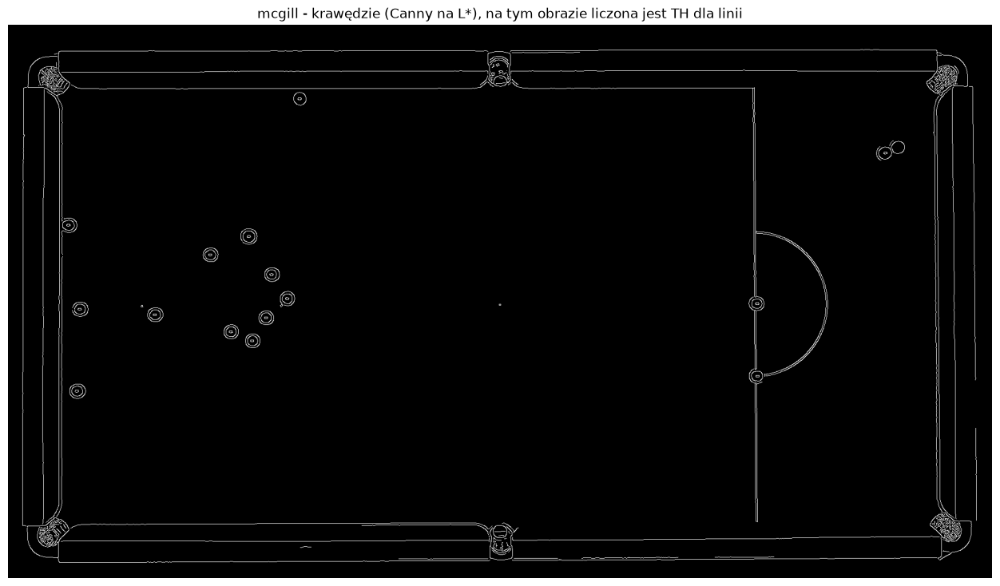

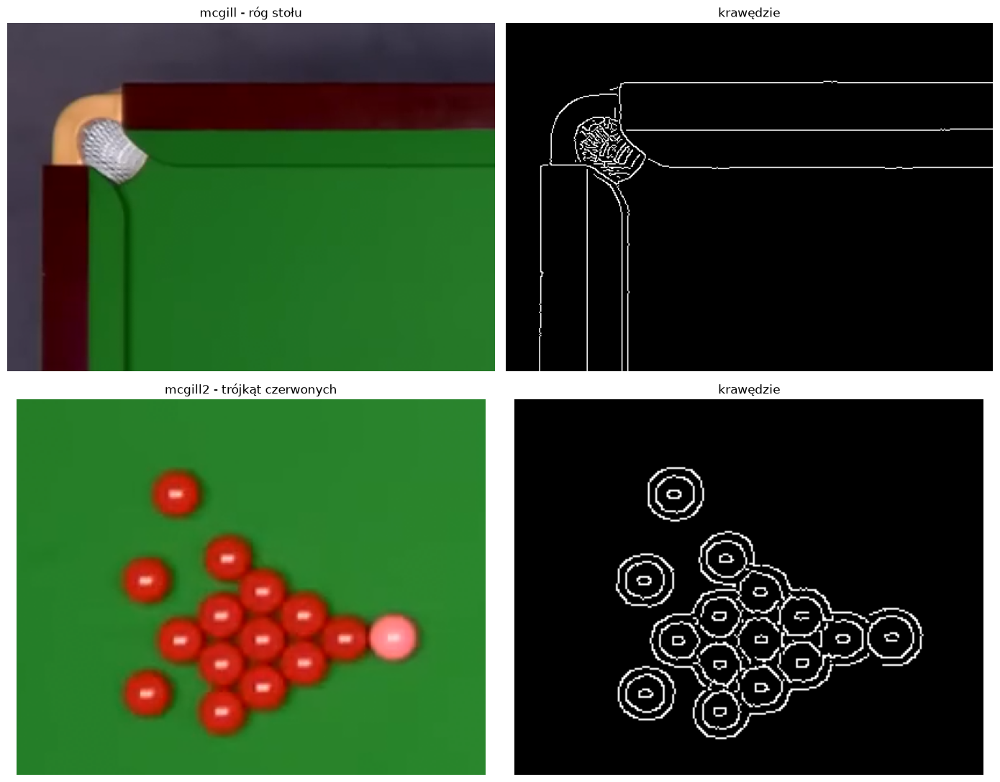

In [5]:
smooth_m, edges_m = preprocess(mcgill)
smooth_m2, edges_m2 = preprocess(mcgill2)

show(edges_m, 'mcgill - krawędzie (Canny na L*), na tym obrazie liczona jest TH dla linii')
show_grid([mcgill[ROI_CORNER], edges_m[ROI_CORNER], mcgill2[ROI_PACK], edges_m2[ROI_PACK]],
          ['mcgill - róg stołu', 'krawędzie', 'mcgill2 - trójkąt czerwonych', 'krawędzie'],
          ncols=2, figsize=(14, 11))

Krawędzie są czyste: każda bila to zamknięty okrąg (także w trójkącie - widać szczeliny między bilami), a sukno jest puste.
Przy każdej bandzie widać jednak **trzy równoległe krawędzie**: zewnętrzną krawędź drewnianej ramy, granicę sukno/drewno oraz „nos” bandy (gumowa krawędź, od której odbijają się bile).
Do tego linia baulk, półkole D i łuzy. Wszystkie te elementy dadzą w TH dodatkowe detekcje, które trzeba będzie odfiltrować.

## 2. Transformacja Hougha dla linii (bandy)

`cv2.HoughLines(image, rho, theta, threshold)`:
* `rho`, `theta` - rozdzielczość akumulatora (odległość od początku układu w px i kąt normalnej w radianach),
* `threshold` - minimalna liczba głosów (pikseli krawędzi), żeby prosta została zwrócona.

Używam wariantu `HoughLinesWithAccumulator`, który poza $(\rho, \theta)$ zwraca liczbę głosów - przyda się w post-processingu.

In [6]:
def hough_lines(edges, rho=1, theta=np.pi/180, threshold=300):
    """Zwraca tablicę (N, 3): rho, theta, liczba głosów."""
    L = cv2.HoughLinesWithAccumulator(edges, rho, theta, threshold)
    return np.zeros((0, 3)) if L is None else L.reshape(-1, 3)

def draw_lines(img, lines, color=(0, 255, 255), thickness=2):
    out = img.copy()
    for rho, theta in np.asarray(lines)[:, :2]:
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        p1 = (int(x0 - 4000 * b), int(y0 + 4000 * a))
        p2 = (int(x0 + 4000 * b), int(y0 - 4000 * a))
        cv2.line(out, p1, p2, color, thickness, cv2.LINE_AA)
    return out

def line_pos(rho, theta, shape):
    """Klasyfikuje prostą jako poziomą 'H' / pionową 'V' i zwraca jej położenie:
    y w środkowej kolumnie (dla H) albo x w środkowym wierszu (dla V)."""
    H, W = shape[:2]
    if abs(np.sin(theta)) > abs(np.cos(theta)):
        return 'H', (rho - W / 2 * np.cos(theta)) / np.sin(theta)
    return 'V', (rho - H / 2 * np.sin(theta)) / np.cos(theta)

def describe(lines, shape):
    """Krótki opis: ile prostych i gdzie leżą (posortowane położenia)."""
    hs = sorted(round(p) for k, p in (line_pos(r, t, shape) for r, t, _ in lines) if k == 'H')
    vs = sorted(round(p) for k, p in (line_pos(r, t, shape) for r, t, _ in lines) if k == 'V')
    other = len(lines) - len(hs) - len(vs)
    return f'{len(lines)} prostych | poziome y={hs} | pionowe x={vs}'

### 2.1. Pierwsze podejście

Parametry „z dokumentacji”: `rho=1`, `theta=1°`, `threshold=200`.

24 prostych | poziome y=[49, 90, 92, 124, 973, 976, 1005, 1007, 1011, 1042, 1048] | pionowe x=[29, 68, 70, 100, 105, 1457, 1458, 1460, 1808, 1812, 1813, 1848, 1848]


<Axes: title={'center': 'mcgill: rho=1, theta=1°, threshold=200'}>

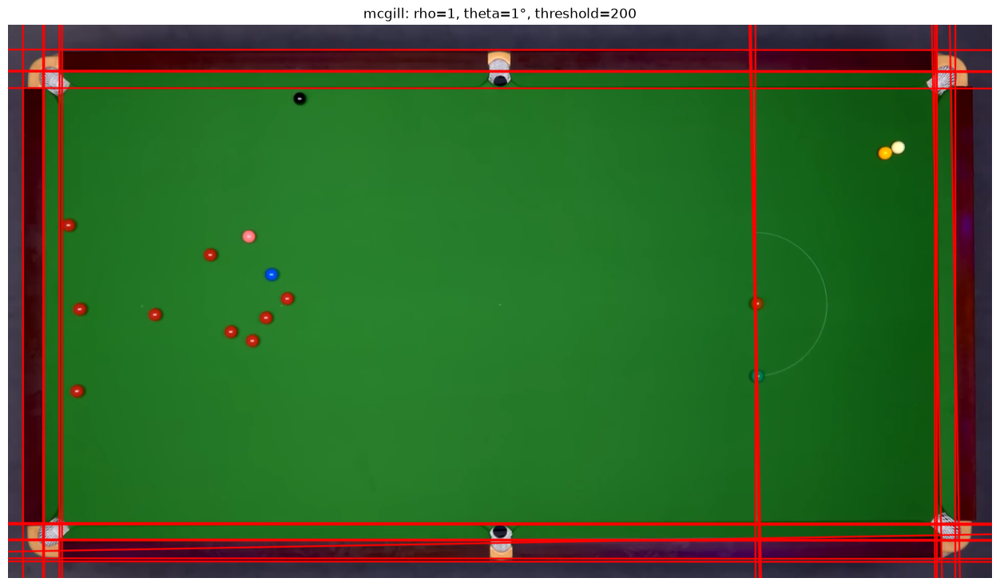

In [7]:
L0 = hough_lines(edges_m, 1, np.pi/180, 200)
print(describe(L0, mcgill.shape))
show(draw_lines(mcgill, L0, (0, 0, 255)), 'mcgill: rho=1, theta=1°, threshold=200')

Zgodnie z oczekiwaniami wynik jest zły:
* przy każdej bandzie jest po kilka prostych (wspomniane trzy równoległe krawędzie, każda często w 2-3 wariantach różniących się o 1 px / 1°),
* wykryta została linia baulk (x ≈ 1458).

Naturalny pomysł - podnieść próg - sprawdzam poniżej.

### 2.2. Wpływ `threshold` i `theta`

theta=1.00°, threshold=200       24 prostych | poziome y=[49, 90, 92, 124, 973, 976, 1005, 1007, 1011, 1042, 1048] | pionowe x=[29, 68, 70, 100, 105, 1457, 1458, 1460, 1808, 1812, 1813, 1848, 1848]
theta=1.00°, threshold=600       3 prostych | poziome y=[49, 90, 124] | pionowe x=[]
theta=0.25°, threshold=600       7 prostych | poziome y=[49, 90, 124, 1006, 1046] | pionowe x=[1815, 1886]
theta=0.25°, threshold=300       43 prostych | poziome y=[49, 49, 51, 87, 89, 90, 92, 123, 124, 125, 972, 973, 1004, 1006, 1007, 1007, 1009, 1010, 1041, 1042, 1043, 1046, 1047] | pionowe x=[29, 29, 68, 68, 100, 100, 105, 105, 1456, 1458, 1458, 1459, 1810, 1810, 1814, 1815, 1846, 1846, 1848, 1886]


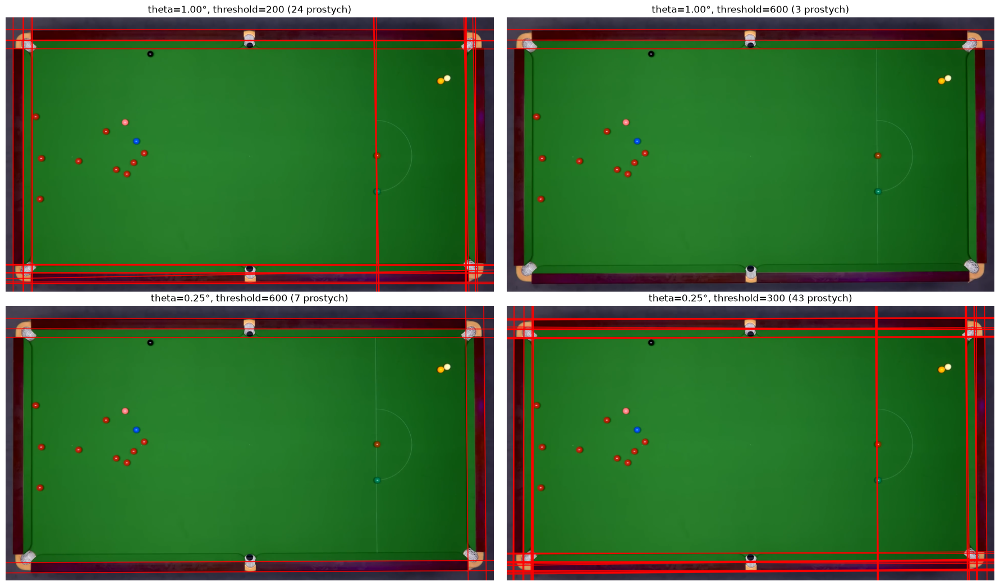

In [8]:
configs = [(np.pi/180, 200), (np.pi/180, 600), (np.pi/720, 600), (np.pi/720, 300)]
imgs, titles = [], []
for theta, thr in configs:
    L = hough_lines(edges_m, 1, theta, thr)
    name = f'theta={np.degrees(theta):.2f}°, threshold={thr}'
    print(f'{name:32s}', describe(L, mcgill.shape))
    imgs.append(draw_lines(mcgill, L, (0, 0, 255)))
    titles.append(f'{name} ({len(L)} prostych)')
show_grid(imgs, titles, ncols=2, figsize=(18, 10.5))

* **`threshold`**: przy 200 głosach dostajemy kilkadziesiąt prostych, przy 600 zostają 3 - wszystkie przy **górnej** bandzie. Znikają za to pozostałe bandy:
  * lewa i prawa, bo krótkie bandy (ok. 800 px między łuzami narożnymi) mają po ok. 400-600 pikseli krawędzi, czyli mniej niż próg,
  * prawa i dolna także z powodu perspektywy: kamera nie jest idealnie nad stołem i te bandy są nachylone o ok. 0,25-0,5°. Przy rozdzielczości kąta 1° piksele jednej krawędzi rozkładają głosy między dwie sąsiednie komórki akumulatora i żadna nie zbiera kompletu.

  Samym progiem nie da się więc tego wyczyścić: zanim znikną duplikaty, znikają prawdziwe bandy.
* **`theta`**: przy 0,25° nachylone bandy dostają pełną liczbę głosów - przy tym samym progu 600 pojawia się dolna (y ≈ 1006) i prawa (x ≈ 1815) banda. Ceną jest więcej niemal identycznych prostych (każda krawędź „trafia” w kilka sąsiednich, drobnych komórek kąta), ale te łatwo scalić w post-processingu.
* **`threshold=300`** (przy `theta=0.25°`): wybieram wartość poniżej poparcia najkrótszej bandy (ok. 400 głosów w najgorszym przypadku), więc żadna banda nie ginie, a odcina krótkie przypadkowe zbiory pikseli (bile, półkole D). Długie bandy są przerwane środkową łuzą - nie ma to znaczenia, bo `HoughLines` zwraca proste nieskończone, więc obie połówki głosują na tę samą parę $(\rho, \theta)$. Dlatego oczekuję **4 prostych**, a nie 6.
* **`rho=1`** - zostawiam: równoległe krawędzie przy bandzie są oddalone o 30-40 px, więc rozdzielczość 1 px ich nie skleja, a daje dokładne położenie.

Mimo dobrych parametrów nadal mamy po 3 krawędzie na bandę + duplikaty + linię baulk. Pora na post-processing.

### 2.3. Post-processing linii

1. **Orientacja**: zostawiam tylko proste prawie poziome/pionowe (odchylenie < 5°).
2. **Położenie**: banda musi leżeć w pasie 15% szerokości/wysokości obrazu przy jego krawędzi - to usuwa linię baulk i inne proste przez środek stołu. Każdą prostą przypisuję do jednej z czterech stron: góra / dół / lewo / prawo.
3. **Scalanie duplikatów (NMS)**: proste tej samej strony różniące się o < 10 px położenia i < 2° kąta traktuję jako tę samą krawędź, zostawiam tę z największą liczbą głosów.
4. **Wybór krawędzi bandy**: z ~3 kandydatów na stronę wybieram **granicę sukno/drewno**, korzystając z koloru. Dla każdej prostej mierzę, jaki ułamek pikseli 8 px w głąb stołu jest zielonym suknem, i odejmuję ułamek 8 px na zewnątrz. Granica sukno/drewno ma wynik ok. 0,8 (zielone tylko po jednej stronie), a zewnętrzna krawędź ramy i nos bandy ok. 0 (po obu stronach to samo: drewno albo sukno).

Liczba głosów nie wystarcza do wyboru, bo dla różnych band „wygrywają” różne krawędzie (raz rama, raz nos, raz granica sukna). Kryterium kolorystyczne jest jednoznaczne.
Granica sukno/drewno ma też tę zaletę, że razem z bandami wyznacza dokładnie zieloną powierzchnię stołu, a jej narożniki to po prostu przecięcia prostych.

In [9]:
LINE_RHO, LINE_THETA, LINE_THR = 1, np.pi/720, 300
MAX_TILT_DEG = 5        # dopuszczalne odchylenie od poziomu/pionu
BORDER_FRAC = 0.15      # banda leży w pasie 15% przy krawędzi obrazu
NMS_POS, NMS_ANGLE = 10, np.radians(2)
SIDE_OFFSET = 8         # odległość próbkowania koloru po obu stronach prostej [px]
SIDES = ('top', 'bottom', 'left', 'right')

def cloth_mask(img_bgr):
    """Maska zielonego sukna (HSV)."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    return cv2.inRange(hsv, (45, 100, 60), (80, 255, 255))

def tilt_deg(theta):
    d = np.degrees(theta)
    return min(abs(d - 90), d, 180 - d)

def nms_lines(lines, shape):
    keep = []
    for r, t, v in sorted(lines, key=lambda l: -l[2]):
        k, p = line_pos(r, t, shape)
        duplicate = False
        for r2, t2, _ in keep:
            k2, p2 = line_pos(r2, t2, shape)
            dt = abs(t - t2); dt = min(dt, np.pi - dt)
            if k == k2 and abs(p - p2) < NMS_POS and dt < NMS_ANGLE:
                duplicate = True; break
        if not duplicate:
            keep.append((r, t, v))
    return keep

def cloth_side_score(rho, theta, mask, off=SIDE_OFFSET):
    """Ułamek sukna po stronie środka obrazu minus ułamek sukna po stronie zewnętrznej."""
    H, W = mask.shape
    a, b = np.cos(theta), np.sin(theta)
    s = np.linspace(-4000, 4000, 8000)
    x, y = a * rho - b * s, b * rho + a * s
    inside = (x >= off) & (x < W - off) & (y >= off) & (y < H - off)
    x, y = x[inside], y[inside]
    if len(x) == 0:
        return -1.0
    sgn = np.sign((W / 2 - a * rho) * a + (H / 2 - b * rho) * b)  # normalna skierowana do środka
    def frac(d):
        xs = np.clip((x + sgn * d * a).astype(int), 0, W - 1)
        ys = np.clip((y + sgn * d * b).astype(int), 0, H - 1)
        return (mask[ys, xs] > 0).mean()
    return frac(off) - frac(-off)

def split_sides(lines, shape):
    H, W = shape[:2]
    sides = {s: [] for s in SIDES}
    for r, t, v in lines:
        if tilt_deg(t) >= MAX_TILT_DEG:
            continue
        k, p = line_pos(r, t, shape)
        if k == 'H':
            if p < BORDER_FRAC * H: sides['top'].append((r, t, v))
            elif p > (1 - BORDER_FRAC) * H: sides['bottom'].append((r, t, v))
        else:
            if p < BORDER_FRAC * W: sides['left'].append((r, t, v))
            elif p > (1 - BORDER_FRAC) * W: sides['right'].append((r, t, v))
    return sides

def select_cushions(img_bgr, lines, verbose=False):
    """Zwraca słownik strona -> (rho, theta) wybranej krawędzi bandy."""
    mask = cloth_mask(img_bgr)
    sides = split_sides(lines, img_bgr.shape)
    result = {}
    for side, cands in sides.items():
        cands = nms_lines(cands, img_bgr.shape)
        if not cands:
            if verbose: print(f'{side:6s}: brak kandydatów!')
            continue
        scored = [(cloth_side_score(r, t, mask), v, r, t) for r, t, v in cands]
        best = max(scored)
        result[side] = (best[2], best[3])
        if verbose:
            desc = ', '.join(f'{line_pos(r, t, img_bgr.shape)[1]:.0f}px (głosy {v:.0f}, sukno {s:+.2f})'
                             for s, v, r, t in sorted(scored, key=lambda x: line_pos(x[2], x[3], img_bgr.shape)[1]))
            print(f'{side:6s}: {desc}  ->  wybrano {line_pos(best[2], best[3], img_bgr.shape)[1]:.0f}px')
    return result

def intersect(l1, l2):
    (r1, t1), (r2, t2) = l1, l2
    A = np.array([[np.cos(t1), np.sin(t1)], [np.cos(t2), np.sin(t2)]])
    return np.linalg.solve(A, [r1, r2])

def table_corners(cushions):
    """Narożniki w kolejności: lewy-górny, prawy-górny, prawy-dolny, lewy-dolny."""
    c = cushions
    return np.array([intersect(c['top'], c['left']), intersect(c['top'], c['right']),
                     intersect(c['bottom'], c['right']), intersect(c['bottom'], c['left'])], np.float32)

== mcgill: TH 43 -> orientacja+położenie 39 -> NMS 12 -> wybór 4
top   : 49px (głosy 631, sukno +0.00), 90px (głosy 915, sukno +0.87), 124px (głosy 866, sukno +0.04)  ->  wybrano 90px
bottom: 972px (głosy 566, sukno +0.04), 1006px (głosy 872, sukno +0.88), 1046px (głosy 761, sukno +0.00)  ->  wybrano 1006px
left  : 29px (głosy 489, sukno +0.00), 68px (głosy 412, sukno +0.80), 105px (głosy 479, sukno +0.02)  ->  wybrano 68px
right : 1815px (głosy 639, sukno +0.04), 1846px (głosy 484, sukno +0.79), 1886px (głosy 623, sukno +0.00)  ->  wybrano 1846px

== mcgill2: TH 37 -> orientacja+położenie 32 -> NMS 11 -> wybór 4
top   : 50px (głosy 733, sukno +0.00), 89px (głosy 880, sukno +0.87), 123px (głosy 652, sukno +0.04)  ->  wybrano 89px
bottom: 1005px (głosy 877, sukno +0.88), 1045px (głosy 715, sukno +0.00)  ->  wybrano 1005px
left  : 29px (głosy 457, sukno +0.00), 68px (głosy 436, sukno +0.74), 99px (głosy 607, sukno +0.03)  ->  wybrano 68px
right : 1815px (głosy 679, sukno +0.04), 1845px (

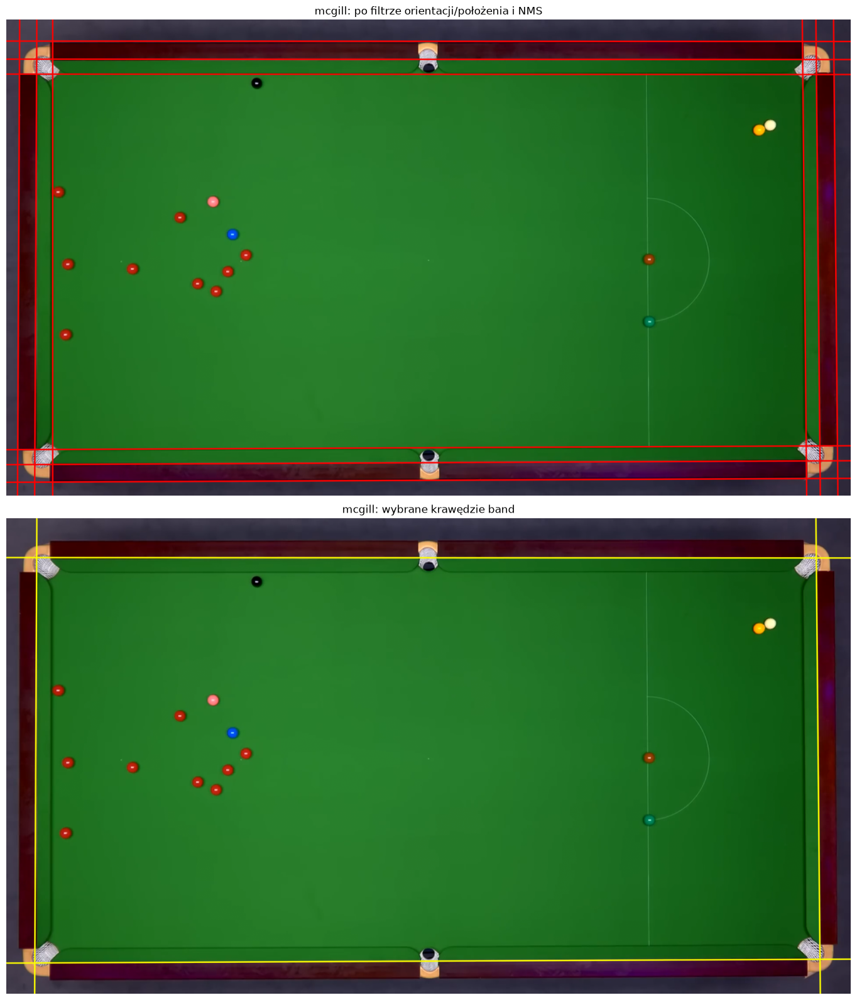

In [10]:
for name, img, edges in [('mcgill', mcgill, edges_m), ('mcgill2', mcgill2, edges_m2)]:
    raw = hough_lines(edges, LINE_RHO, LINE_THETA, LINE_THR)
    sides = split_sides(raw, img.shape)
    n_after_filter = sum(len(v) for v in sides.values())
    n_after_nms = sum(len(nms_lines(v, img.shape)) for v in sides.values())
    print(f'== {name}: TH {len(raw)} -> orientacja+położenie {n_after_filter} -> NMS {n_after_nms} -> wybór 4')
    cushions = select_cushions(img, raw, verbose=True)
    print()

cushions_m = select_cushions(mcgill, hough_lines(edges_m, LINE_RHO, LINE_THETA, LINE_THR))
nms_all = [l for v in split_sides(hough_lines(edges_m, LINE_RHO, LINE_THETA, LINE_THR), mcgill.shape).values()
           for l in nms_lines(v, mcgill.shape)]
show_grid([draw_lines(mcgill, nms_all, (0, 0, 255)), draw_lines(mcgill, [(*l, 0) for l in cushions_m.values()])],
          ['mcgill: po filtrze orientacji/położenia i NMS', 'mcgill: wybrane krawędzie band'],
          ncols=1, figsize=(14, 16))

Kolejne kroki redukują kilkadziesiąt prostych z TH do 3-4 kandydatów na stronę, a kryterium sukna wybiera spośród nich zawsze granicę sukno/drewno - jej wynik (≈ +0,8) wyraźnie odstaje od pozostałych (≈ 0). Wynik nie dochodzi do 1, bo na wysokości łuz po wewnętrznej stronie nie ma sukna.

Dla porównania - sama liczba głosów wybrałaby na różnych bandach różne krawędzie (w `mcgill`: góra i dół - granica sukna, lewa - zewnętrzna krawędź ramy, prawa - nos bandy), więc wynik nie byłby spójny.

## 3. Transformacja Hougha dla okręgów (bile)

`cv2.HoughCircles(image, method, dp, minDist, param1, param2, minRadius, maxRadius)` z metodą `HOUGH_GRADIENT`:
* `image` - obraz w odcieniach szarości (**nie** mapa krawędzi: metoda sama liczy Canny'ego, a kierunek gradientu bierze z Sobela, więc podanie binarnych krawędzi psuje kierunki gradientu). Podaję wygładzony kanał L\* z przetwarzania wstępnego,
* `dp` - odwrotność rozdzielczości akumulatora,
* `minDist` - minimalna odległość między środkami wykrytych okręgów,
* `param1` - górny próg Canny'ego,
* `param2` - próg akumulatora środków (im mniejszy, tym więcej - także fałszywych - okręgów),
* `minRadius`, `maxRadius` - zakres promieni.

### 3.1. Pierwsze podejście

Parametry „domyślne”: bez ograniczeń promienia, `param2=30`.

liczba okręgów: 1191 | mediana promienia: 261 px


<Axes: title={'center': 'mcgill: bez ograniczeń promienia, param2=30 -> 1191 okręgów'}>

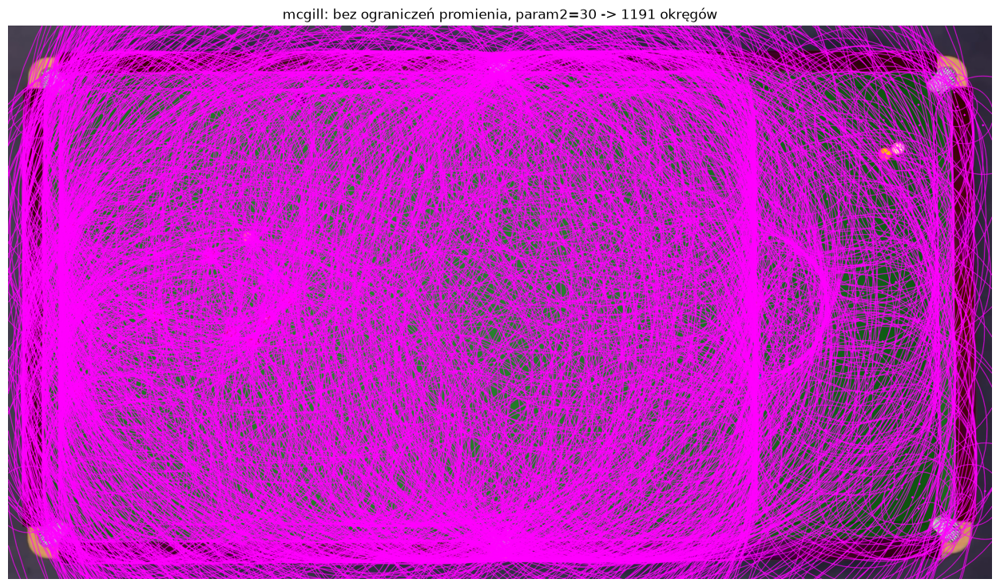

In [11]:
def hough_circles(smooth, dp=1, min_dist=20, param1=CANNY_HI, param2=15, min_r=9, max_r=18):
    C = cv2.HoughCircles(smooth, cv2.HOUGH_GRADIENT, dp, min_dist,
                         param1=param1, param2=param2, minRadius=min_r, maxRadius=max_r)
    return np.zeros((0, 3)) if C is None else C.reshape(-1, 3)

def draw_circles(img, circles, color=(255, 0, 255), thickness=2):
    out = img.copy()
    for x, y, r in circles:
        cv2.circle(out, (int(round(x)), int(round(y))), int(round(r)), color, thickness, cv2.LINE_AA)
        cv2.circle(out, (int(round(x)), int(round(y))), 2, color, -1)
    return out

C0 = hough_circles(smooth_m, min_dist=20, param2=30, min_r=0, max_r=0)
print('liczba okręgów:', len(C0), '| mediana promienia: %.0f px' % np.median(C0[:, 2]))
show(draw_circles(mcgill, C0, thickness=1), f'mcgill: bez ograniczeń promienia, param2=30 -> {len(C0)} okręgów')

Ponad tysiąc okręgów o promieniach rzędu setek pikseli. Bez ograniczenia promienia akumulator zbiera głosy od wszystkiego: band, półkola D, łuz. Długie, proste krawędzie band dają mnóstwo głosów dla dużych okręgów, które je „muskają”.

### 3.2. Zakres promieni

Bile na tych kadrach mają średnicę ok. 25-27 px (sprawdzone na powiększeniach; mediana promieni wykrytych bil w `mcgill` to 12,5 px). Ustawiam `minRadius=9`, `maxRadius=18`, czyli ok. ±35% zapasu.
Szerszy zakres (np. 5-30) przepuszcza więcej fałszywych okręgów (43 zamiast 28 w `mcgill`, głównie przy łuzach), a w trójkącie `mcgill2` część bil przegrywa z większymi okręgami obejmującymi kilka bil (19 zamiast 22). Bez ograniczenia promienia wyniki są bezużyteczne.

In [12]:
def count_inside(circles, cushions, margin=40):
    """Pomocniczo do eksperymentów: ile okręgów leży wewnątrz stołu (post-processing opisany w 3.5)."""
    return len(filter_circles(circles, cushions, margin)) if len(circles) else 0

def filter_circles(circles, cushions, margin=40):
    lines = [cushions[s] for s in SIDES]
    poly = table_corners(cushions)
    keep = []
    for x, y, r in circles:
        if cv2.pointPolygonTest(poly, (float(x), float(y)), False) <= 0:
            continue
        if min(abs(x * np.cos(t) + y * np.sin(t) - rho) for rho, t in lines) < margin:
            continue
        keep.append((x, y, r))
    return np.array(keep).reshape(-1, 3)

cushions_m2 = select_cushions(mcgill2, hough_lines(edges_m2, LINE_RHO, LINE_THETA, LINE_THR))
GT = {'mcgill': 16, 'mcgill2': 22}   # policzone ręcznie
for min_r, max_r in [(0, 0), (5, 30), (9, 18)]:
    row = []
    for name, sm, cu in [('mcgill', smooth_m, cushions_m), ('mcgill2', smooth_m2, cushions_m2)]:
        C = hough_circles(sm, param2=15, min_r=min_r, max_r=max_r)
        row.append(f'{name}: {len(C):4d} wszystkich, {count_inside(C, cu):3d} na stole (prawda: {GT[name]})')
    print(f'r = [{min_r:2d}, {max_r:2d}]  |  ' + '  |  '.join(row))

r = [ 0,  0]  |  mcgill: 2929 wszystkich, 2270 na stole (prawda: 16)  |  mcgill2: 2899 wszystkich, 2277 na stole (prawda: 22)
r = [ 5, 30]  |  mcgill:   43 wszystkich,  16 na stole (prawda: 16)  |  mcgill2:   46 wszystkich,  19 na stole (prawda: 22)
r = [ 9, 18]  |  mcgill:   28 wszystkich,  16 na stole (prawda: 16)  |  mcgill2:   34 wszystkich,  22 na stole (prawda: 22)


### 3.3. `param2` (próg akumulatora) i `param1` (próg Canny'ego)

Pokazuję trójkąt w `mcgill2`, bo tam różnice są najlepiej widoczne.

param2=30: mcgill  15/16, mcgill2  14/22  (na stole / prawda)
param2=15: mcgill  16/16, mcgill2  22/22  (na stole / prawda)


param2= 5: mcgill  56/16, mcgill2  60/22  (na stole / prawda)
param1=150 (param2=15): mcgill   4/16, mcgill2   4/22
param1= 30 (param2=15): mcgill  16/16, mcgill2  22/22


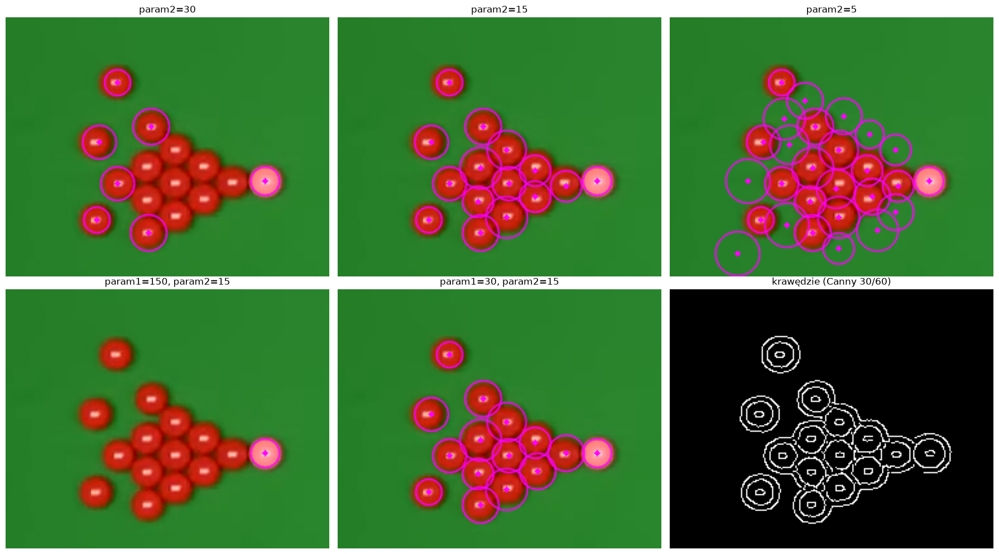

In [13]:
imgs, titles = [], []
for p2 in [30, 15, 5]:
    C = hough_circles(smooth_m2, param2=p2)
    print(f'param2={p2:2d}: mcgill {count_inside(hough_circles(smooth_m, param2=p2), cushions_m):3d}/16, '
          f'mcgill2 {count_inside(C, cushions_m2):3d}/22  (na stole / prawda)')
    imgs.append(draw_circles(mcgill2, C, thickness=1)[ROI_PACK]); titles.append(f'param2={p2}')
for p1 in [150, 30]:
    C = hough_circles(smooth_m2, param1=p1, param2=15)
    print(f'param1={p1:3d} (param2=15): mcgill {count_inside(hough_circles(smooth_m, param1=p1), cushions_m):3d}/16, '
          f'mcgill2 {count_inside(C, cushions_m2):3d}/22')
    imgs.append(draw_circles(mcgill2, C, thickness=1)[ROI_PACK]); titles.append(f'param1={p1}, param2=15')
imgs.append(edges_m2[ROI_PACK]); titles.append('krawędzie (Canny 30/60)')
show_grid(imgs, titles, ncols=3, figsize=(18, 10))

* **`param2=30`** - za wysoki: część bil w trójkącie (i jedna bila w `mcgill`) nie zbiera wystarczającej liczby głosów, bo ich brzegi są częściowo zasłonięte przez sąsiadów, więc okrąg krawędzi jest niepełny.
* **`param2=5`** - za niski: pojawiają się dziesiątki fałszywych okręgów (w szczelinach między bilami, na szumie sukna, wokół odblasków).
* **`param2=15`** - wszystkie bile wykryte, fałszywe okręgi na suknie nie występują. Wybieram tę wartość. W zakresie ok. 10-15 wynik jest taki sam (sprawdzone na wszystkich czterech obrazach), więc wybór nie jest „na ostrzu noża”. Przy 20 zaczyna już brakować pojedynczych bil w trójkącie.
* **`param1=150`** - wewnętrzny Canny z tak wysokim progiem gubi słabe krawędzie bila/sukno. Zostają tylko 4 bile o największym kontraście (w pokazanym RoI - jedynie różowa). **`param1=30`** - daje ten sam wynik co 60, bo przy wygładzonym obrazie nie ma już dużo szumu. Zostawiam `param1=60`, czyli dokładnie te krawędzie, które pokazałem w przetwarzaniu wstępnym.

### 3.4. `minDist` i `dp`

minDist= 5: mcgill  22/16, mcgill2  27/22
minDist=20: mcgill  16/16, mcgill2  22/22
minDist=40: mcgill  15/16, mcgill2  14/22
dp=2: mcgill  54/16, mcgill2  49/22


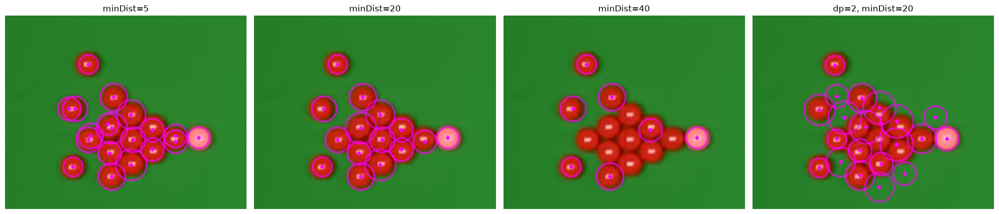

In [14]:
imgs, titles = [], []
for md_ in [5, 20, 40]:
    C = hough_circles(smooth_m2, min_dist=md_)
    print(f'minDist={md_:2d}: mcgill {count_inside(hough_circles(smooth_m, min_dist=md_), cushions_m):3d}/16, '
          f'mcgill2 {count_inside(C, cushions_m2):3d}/22')
    imgs.append(draw_circles(mcgill2, C, thickness=1)[ROI_PACK]); titles.append(f'minDist={md_}')
for dp in [2]:
    C = hough_circles(smooth_m2, dp=dp)
    print(f'dp={dp}: mcgill {count_inside(hough_circles(smooth_m, dp=dp), cushions_m):3d}/16, '
          f'mcgill2 {count_inside(C, cushions_m2):3d}/22')
    imgs.append(draw_circles(mcgill2, C, thickness=1)[ROI_PACK]); titles.append(f'dp={dp}, minDist=20')
show_grid(imgs, titles, ncols=4, figsize=(20, 5))

* **`minDist=5`** - kilka okręgów na jedną bilę (koncentryczne lub lekko przesunięte), bo sąsiednie komórki akumulatora wokół środka bili też przekraczają próg.
* **`minDist=40`** - większe niż średnica bili (~27 px), więc ze stykających się bil w trójkącie zostaje tylko część.
* **`minDist=20`** - mniejsze niż średnica (bile stykające się mają środki ~27 px od siebie), ale większe niż promień, więc duplikaty jednej bili są tłumione. Wybieram 20.
* **`dp`** - zostawiam 1 (akumulator w pełnej rozdzielczości). Przy `dp=2` komórka akumulatora jest 2× większa w każdym kierunku i zbiera głosy z większego obszaru, więc ten sam `param2=15` jest w praktyce dużo łagodniejszy: liczba okręgów na stole rośnie do ~50 (mnóstwo fałszywych). Trzeba by od nowa dobierać `param2`, a obraz nie jest na tyle duży, żeby oszczędność czasu miała znaczenie.

### 3.5. Post-processing okręgów

Po dobraniu parametrów jedyne fałszywe detekcje to **łuzy** (siatki i otwory mają okrągłe kształty o podobnym promieniu) oraz okazjonalnie dłoń/kij zawodnika - wszystko poza powierzchnią gry.
Filtr korzysta z wykrytych band:
1. środek okręgu musi leżeć wewnątrz czworokąta wyznaczonego przez 4 proste,
2. środek musi być co najmniej 40 px od każdej bandy. Wykryte proste to granica sukno/drewno, a nos bandy jest ok. 32-35 px dalej w głąb stołu. Bila dotykająca bandy ma więc środek ok. 32 + 13 ≈ 45 px od wykrytej prostej, a łuzy leżą bliżej niż 40 px. Margines 40 px rozdziela te dwa przypadki.

mcgill: 28 okręgów z TH -> 16 po filtrze (prawda: 16), mediana promienia 12.5 px


<Axes: title={'center': 'mcgill: zachowane (fiolet) i odrzucone (czerwony) okręgi'}>

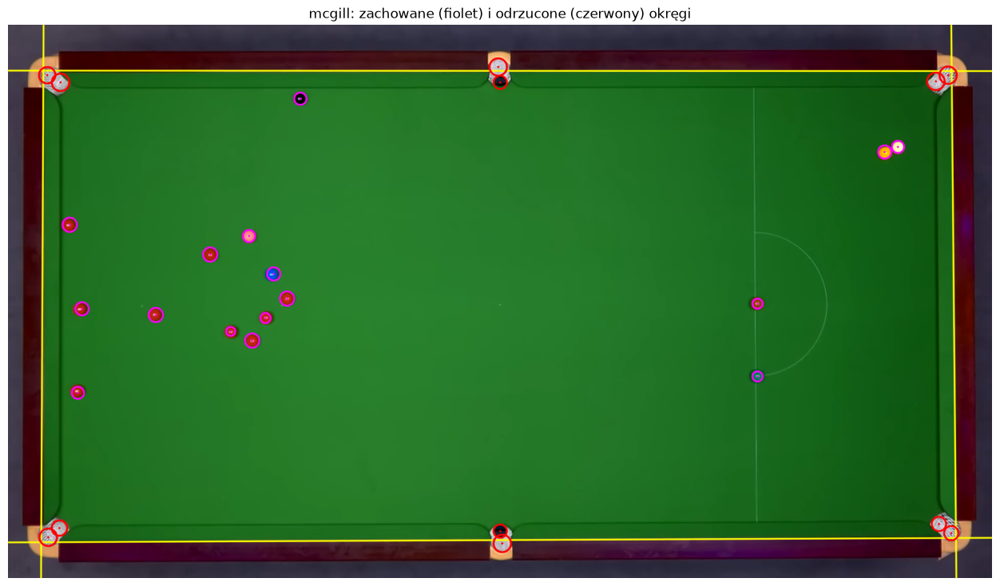

In [15]:
CIRCLE_PARAMS = dict(dp=1, min_dist=20, param1=CANNY_HI, param2=15, min_r=9, max_r=18)
CUSHION_MARGIN = 40

C_raw = hough_circles(smooth_m, **CIRCLE_PARAMS)
C_ok = filter_circles(C_raw, cushions_m, CUSHION_MARGIN)
removed = np.array([c for c in C_raw if not any(np.allclose(c, k) for k in C_ok)]).reshape(-1, 3)
print(f'mcgill: {len(C_raw)} okręgów z TH -> {len(C_ok)} po filtrze (prawda: 16), '
      f'mediana promienia {np.median(C_ok[:, 2]):.1f} px')
vis = draw_lines(mcgill, [(*l, 0) for l in cushions_m.values()])
vis = draw_circles(vis, C_ok)
vis = draw_circles(vis, removed, (0, 0, 255))
show(vis, 'mcgill: zachowane (fiolet) i odrzucone (czerwony) okręgi')

## 4. Pełny potok

Funkcja `detect` przyjmuje obraz BGR i zwraca:
* `circles` - tablica (N, 3): x, y, r bil (w pikselach),
* `cushions` - słownik strona -> $(\rho, \theta)$ prostej bandy,
* `corners` - 4 narożniki stołu (przecięcia band),
* oraz pośrednie obrazy do wizualizacji.

Dodatkowo, ponieważ celem aplikacji jest położenie bil **w układzie stołu**, przeliczam środki bil przez homografię wyznaczoną z narożników na współrzędne znormalizowane: (0, 0) - lewy górny róg, (1, 1) - prawy dolny róg powierzchni sukna.

In [16]:
def detect(img_bgr):
    smooth, edges = preprocess(img_bgr)
    lines = hough_lines(edges, LINE_RHO, LINE_THETA, LINE_THR)
    cushions = select_cushions(img_bgr, lines)
    if len(cushions) < 4:
        raise RuntimeError(f'Wykryto tylko bandy: {list(cushions)}')
    corners = table_corners(cushions)
    circles_raw = hough_circles(smooth, **CIRCLE_PARAMS)
    circles = filter_circles(circles_raw, cushions, CUSHION_MARGIN)
    # homografia: obraz -> znormalizowany układ stołu
    Hm = cv2.getPerspectiveTransform(corners, np.float32([[0, 0], [1, 0], [1, 1], [0, 1]]))
    table_xy = cv2.perspectiveTransform(circles[None, :, :2].astype(np.float32), Hm)[0] if len(circles) else np.zeros((0, 2))
    return dict(circles=circles, cushions=cushions, corners=corners, table_xy=table_xy,
                edges=edges, circles_raw=circles_raw, lines_raw=lines)

def draw_results(img_bgr, res):
    out = draw_lines(img_bgr, [(*l, 0) for l in res['cushions'].values()], (0, 255, 255), 2)
    for x, y in res['corners']:
        cv2.drawMarker(out, (int(x), int(y)), (255, 255, 0), cv2.MARKER_CROSS, 40, 3)
    return draw_circles(out, res['circles'], (255, 0, 255), 2)

def demo(name, img):
    res = detect(img)
    print(f"{name}: wykryto {len(res['circles'])} bil "
          f"(TH dała {len(res['circles_raw'])} okręgów), bandy: {len(res['cushions'])}, "
          f"{len(res['lines_raw'])} prostych z TH")
    _, axes = plt.subplots(3, 1, figsize=(14, 24))
    show(img, f'{name} - wejście', ax=axes[0])
    show(res['edges'], f'{name} - krawędzie', ax=axes[1])
    show(draw_results(img, res), f'{name} - wykryte bandy, narożniki i bile', ax=axes[2])
    plt.tight_layout(); plt.show()
    return res

## 5. Wyniki na pozostałych obrazach

trump: wykryto 12 bil (TH dała 22 okręgów), bandy: 4, 60 prostych z TH


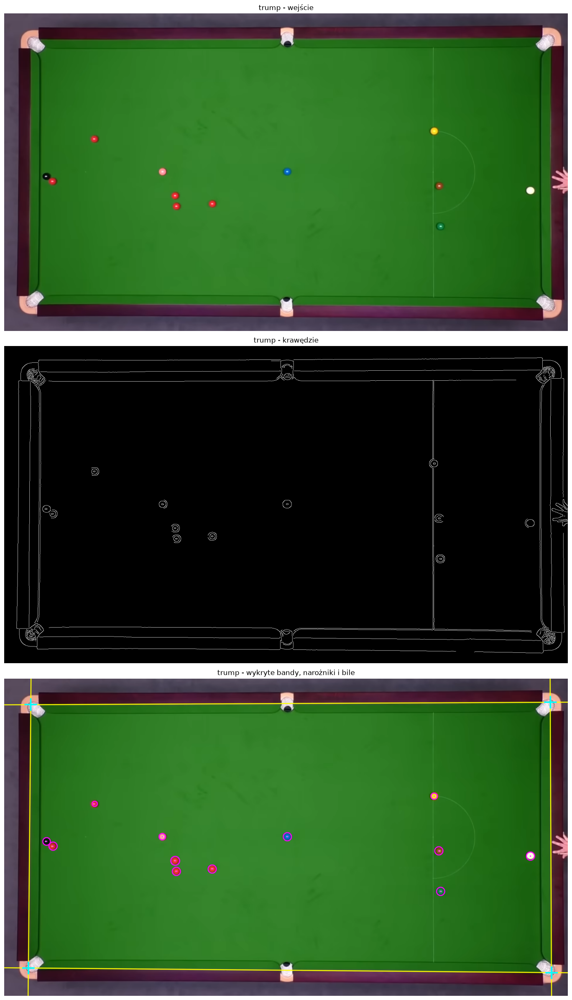

In [17]:
res_trump = demo('trump', trump)

zhao: wykryto 22 bil (TH dała 33 okręgów), bandy: 4, 29 prostych z TH


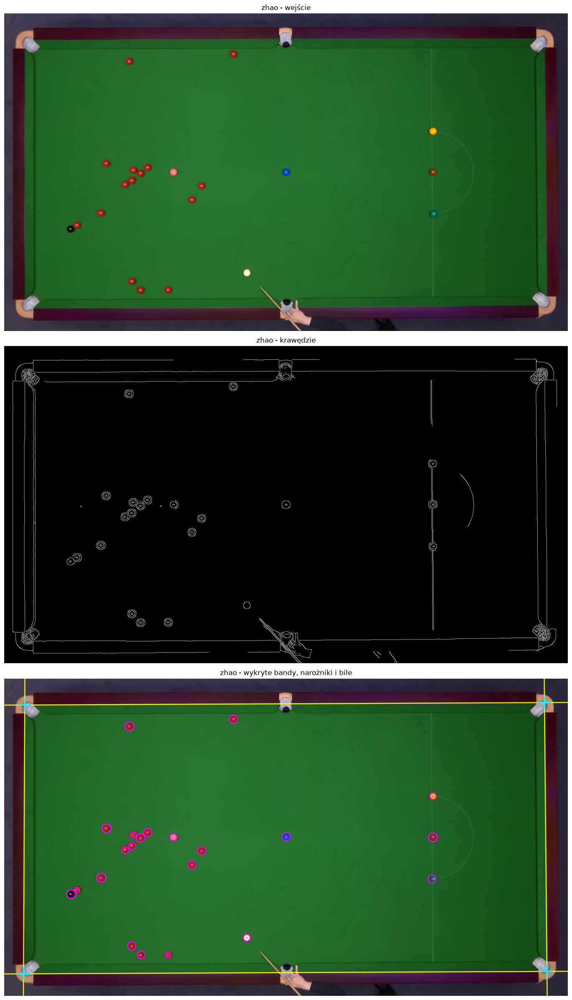

In [18]:
res_zhao = demo('zhao', zhao)

Dla kompletności - obrazy kalibracyjne przepuszczone przez ten sam potok:

mcgill: wykryto 16 bil (TH dała 28 okręgów), bandy: 4, 43 prostych z TH


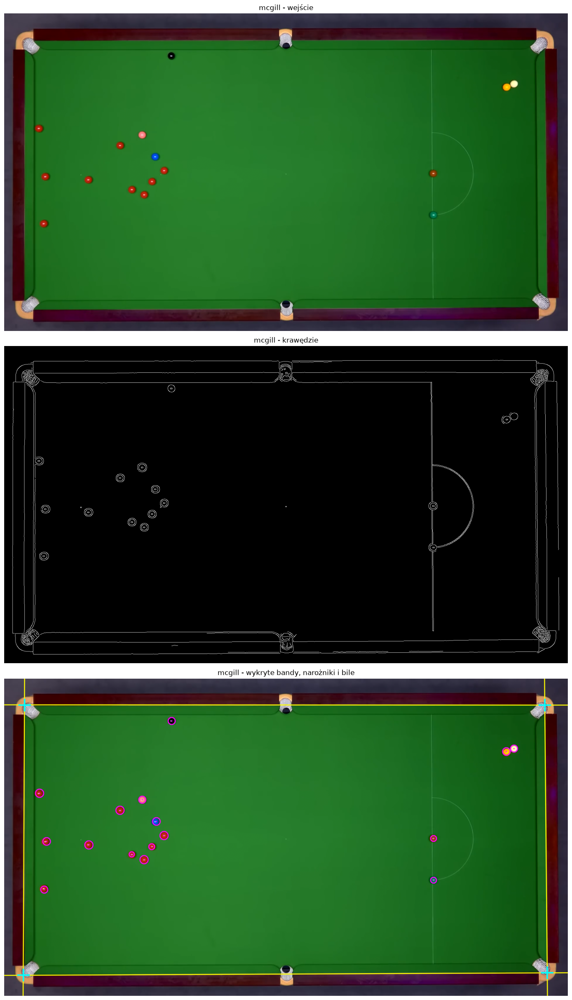

mcgill2: wykryto 22 bil (TH dała 34 okręgów), bandy: 4, 37 prostych z TH


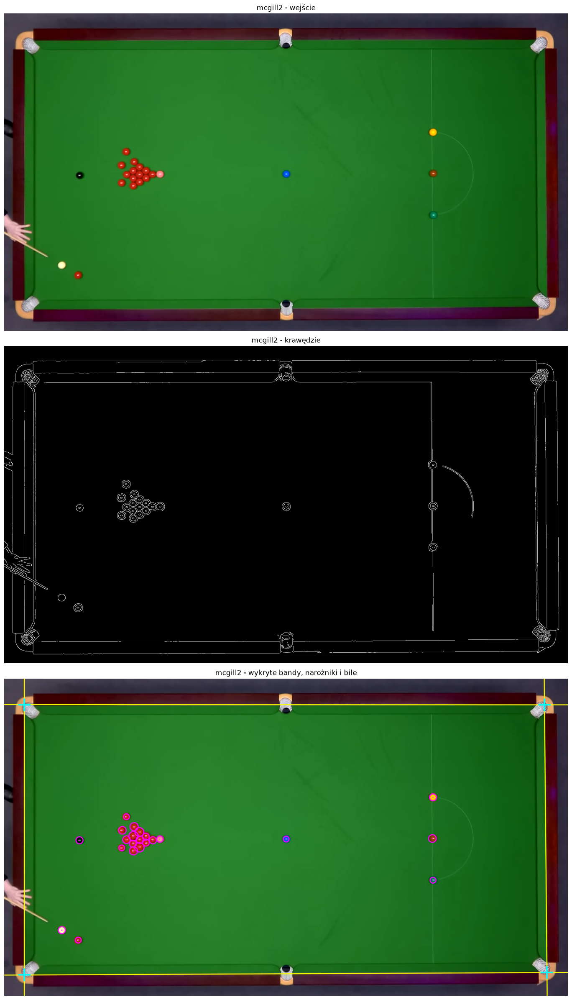

In [19]:
res_mcgill = demo('mcgill', mcgill)
res_mcgill2 = demo('mcgill2', mcgill2)

In [20]:
# przykładowy wynik w układzie stołu (dla zespołu zajmującego się geometrią)
print('zhao: położenia bil w układzie stołu (0..1 wzdłuż, 0..1 w poprzek)')
for (x, y, r), (u, v) in sorted(zip(res_zhao['circles'], res_zhao['table_xy']), key=lambda p: p[1][0]):
    print(f'  piksel ({x:6.1f}, {y:6.1f}), r={r:4.1f}  ->  stół ({u:.3f}, {v:.3f})')

zhao: położenia bil w układzie stołu (0..1 wzdłuż, 0..1 w poprzek)
  piksel ( 227.5,  734.5), r=14.6  ->  stół (0.090, 0.707)
  piksel ( 247.5,  719.5), r= 9.4  ->  stół (0.101, 0.691)
  piksel ( 329.5,  677.5), r=15.1  ->  stół (0.147, 0.645)
  piksel ( 347.5,  509.5), r=14.7  ->  stół (0.157, 0.462)
  piksel ( 411.5,  583.5), r=11.6  ->  stół (0.193, 0.543)
  piksel ( 425.5,  162.5), r=14.7  ->  stół (0.201, 0.082)
  piksel ( 434.5,  910.5), r=13.8  ->  stół (0.206, 0.899)
  piksel ( 435.5,  569.5), r=11.8  ->  stół (0.207, 0.528)
  piksel ( 439.5,  532.5), r=10.3  ->  stół (0.209, 0.487)
  piksel ( 464.5,  542.5), r=14.0  ->  stół (0.223, 0.498)
  piksel ( 466.5,  940.5), r=12.7  ->  stół (0.224, 0.932)
  piksel ( 488.5,  523.5), r=13.8  ->  stół (0.236, 0.478)
  piksel ( 557.5,  940.5), r= 9.6  ->  stół (0.275, 0.933)
  piksel ( 576.5,  539.5), r=11.6  ->  stół (0.286, 0.496)
  piksel ( 638.5,  633.5), r=13.8  ->  stół (0.321, 0.599)
  piksel ( 672.5,  585.5), r=13.8  ->  stół (0.3

## 6. Podsumowanie

**Przetwarzanie wstępne**: kanał L\* + Gauss 5×5 + Canny 30/60. Kluczowy był wybór kanału: w skali szarości czerwone bile na zielonym suknie miały za słabe krawędzie.

**Bandy (`HoughLines`)**: `rho=1`, `theta=0.25°`, `threshold=300`.
Surowa TH daje kilkadziesiąt prostych, bo każda banda ma trzy równoległe krawędzie (rama, granica sukna, nos bandy), każda krawędź trafia w kilka sąsiednich komórek akumulatora, a do tego dochodzi linia baulk.
Rozdzielczość kąta 1° była za mała, bo przez perspektywę prawa i dolna banda są nachylone o ułamek stopnia i ich głosy się rozpraszały. Podnoszenie progu przy 1° usuwało te bandy, zanim usunęło duplikaty.
Post-processing: orientacja → pas przy krawędzi obrazu → NMS → wybór granicy sukno/drewno kryterium kolorystycznym. Na wszystkich 4 obrazach daje dokładnie 4 bandy i 4 narożniki.

**Bile (`HoughCircles`)**: `dp=1`, `minDist=20`, `param1=60`, `param2=15`, promień 9-18 px.
Najważniejszy jest zakres promieni (bez niego > 1000 okręgów), potem `param2` (kompromis: trójkąt vs fałszywe okręgi) i `minDist` (mniejszy niż średnica bili, inaczej giną stykające się bile).
Post-processing usuwa okręgi poza powierzchnią gry, czyli łuzy, dłonie i kij.

**Wyniki**: na wszystkich czterech obrazach liczba wykrytych bil zgadza się z ręcznie policzoną (mcgill 16, mcgill2 22, trump 12, zhao 22).

**Ograniczenia i możliwe źródła błędów**:
* bile stykające się z bandą lub stojące tuż przy łuzie są blisko marginesu 40 px. Bila wpadająca do łuzy zostałaby odrzucona (co zresztą jest pożądane),
* bila częściowo zasłonięta przez kij lub dłoń zawodnika ma niepełny okrąg krawędzi i może nie zebrać 15 głosów,
* zielona bila ma najmniejszy kontrast z suknem i jest najbardziej wrażliwa na `param2`/`param1`,
* bile w ciasnym skupisku są wykrywane, ale ich promienie/środki są mniej dokładne (krawędzie sąsiadów też głosują),
* stałe parametry (promień bili, margines, pasy przy krawędzi) zakładają ten sam kadr co w transmisji - przy innym zbliżeniu trzeba je przeskalować, np. względem wykrytej szerokości stołu,
* wykryte proste to granica sukna, a nie nos bandy. Jeśli zespół od geometrii potrzebuje linii odbicia, trzeba je przesunąć o szerokość bandy (ok. 32-35 px) albo wybrać drugiego kandydata z tej samej listy.